In [1]:

from pathlib import Path
import pandas as pd

runs = Path(
    r"C:\Users\User\Downloads\Tamban_Thesis_Main_Repository"
    r"\Thesis\sardinella-lemuru-ml\notebooks"
    r"\Tamban_Model1_Retrain"
    r"\model1_20261101T161439Z\runs"
)

for name in ["model1_yolo26s", "model1_yolo26s_stage2"]:
    file = runs / name / "results.csv"
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()

    metric = "metrics/mAP50-95(B)"
    idx = df[metric].idxmax()

    print(f"\n{name}")
    print("Completed epochs:", len(df))
    print("Best epoch:", int(df.loc[idx, "epoch"]) + 1)
    print("Best mAP50-95:", round(df.loc[idx, metric], 4))
    print("Latest mAP50-95:", round(df[metric].iloc[-1], 4))



model1_yolo26s
Completed epochs: 241
Best epoch: 197
Best mAP50-95: 0.8623
Latest mAP50-95: 0.8583

model1_yolo26s_stage2
Completed epochs: 17
Best epoch: 5
Best mAP50-95: 0.8386
Latest mAP50-95: 0.7954


MODEL 1 V1 VS V2 COMPARISON
V1: C:\Users\User\Downloads\Tamban_Thesis_Main_Repository\Thesis\sardinella-lemuru-ml\models\fish_detector\weights\model1_fish_parent_detector.pt
V2: C:\Users\User\Downloads\Tamban_Thesis_Main_Repository\Thesis\sardinella-lemuru-ml\notebooks\Tamban_Model1_Retrain\model1_20261101T161439Z\runs\model1_yolo26s\weights\best.pt
Device: NVIDIA GeForce RTX 2050
Same validation dataset: 295 images, 3390 fish

========= V1 =========
Ultralytics 8.4.197  Python-3.14.6 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 2050, 4096MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 224.7±29.7 MB/s, size: 156.8 KB)
val: Scanning C:\Users\User\Downloads\Tamban_Thesis_Main_Repository\Thesis\sardinella-lemuru-ml\notebooks\tamban_model1_1900_work\yolo_cleaned\labels\val... 295 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 295/295 1.5Kit/s 0.2s<0.3s
val: New cache created: C:\Users\User\Downl

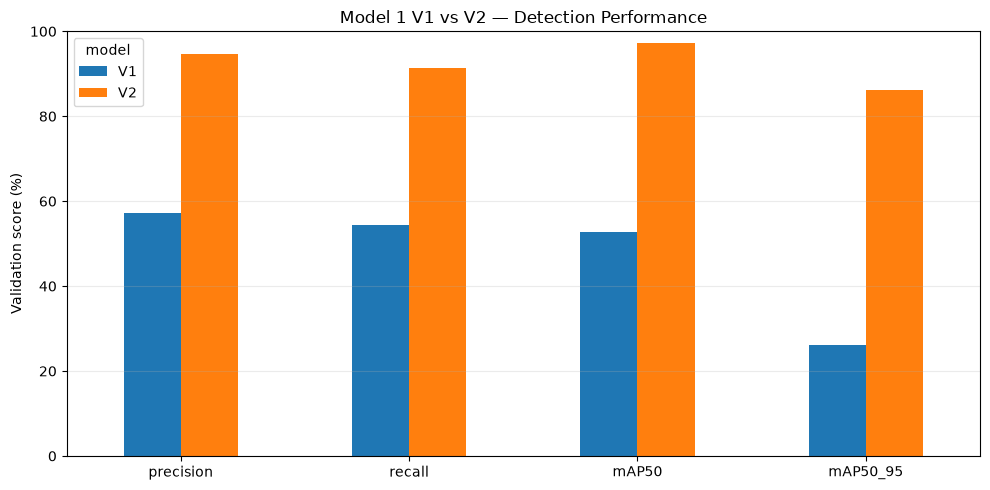

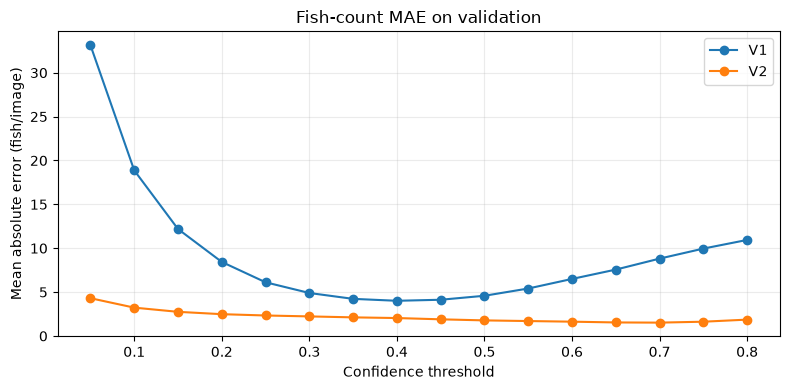

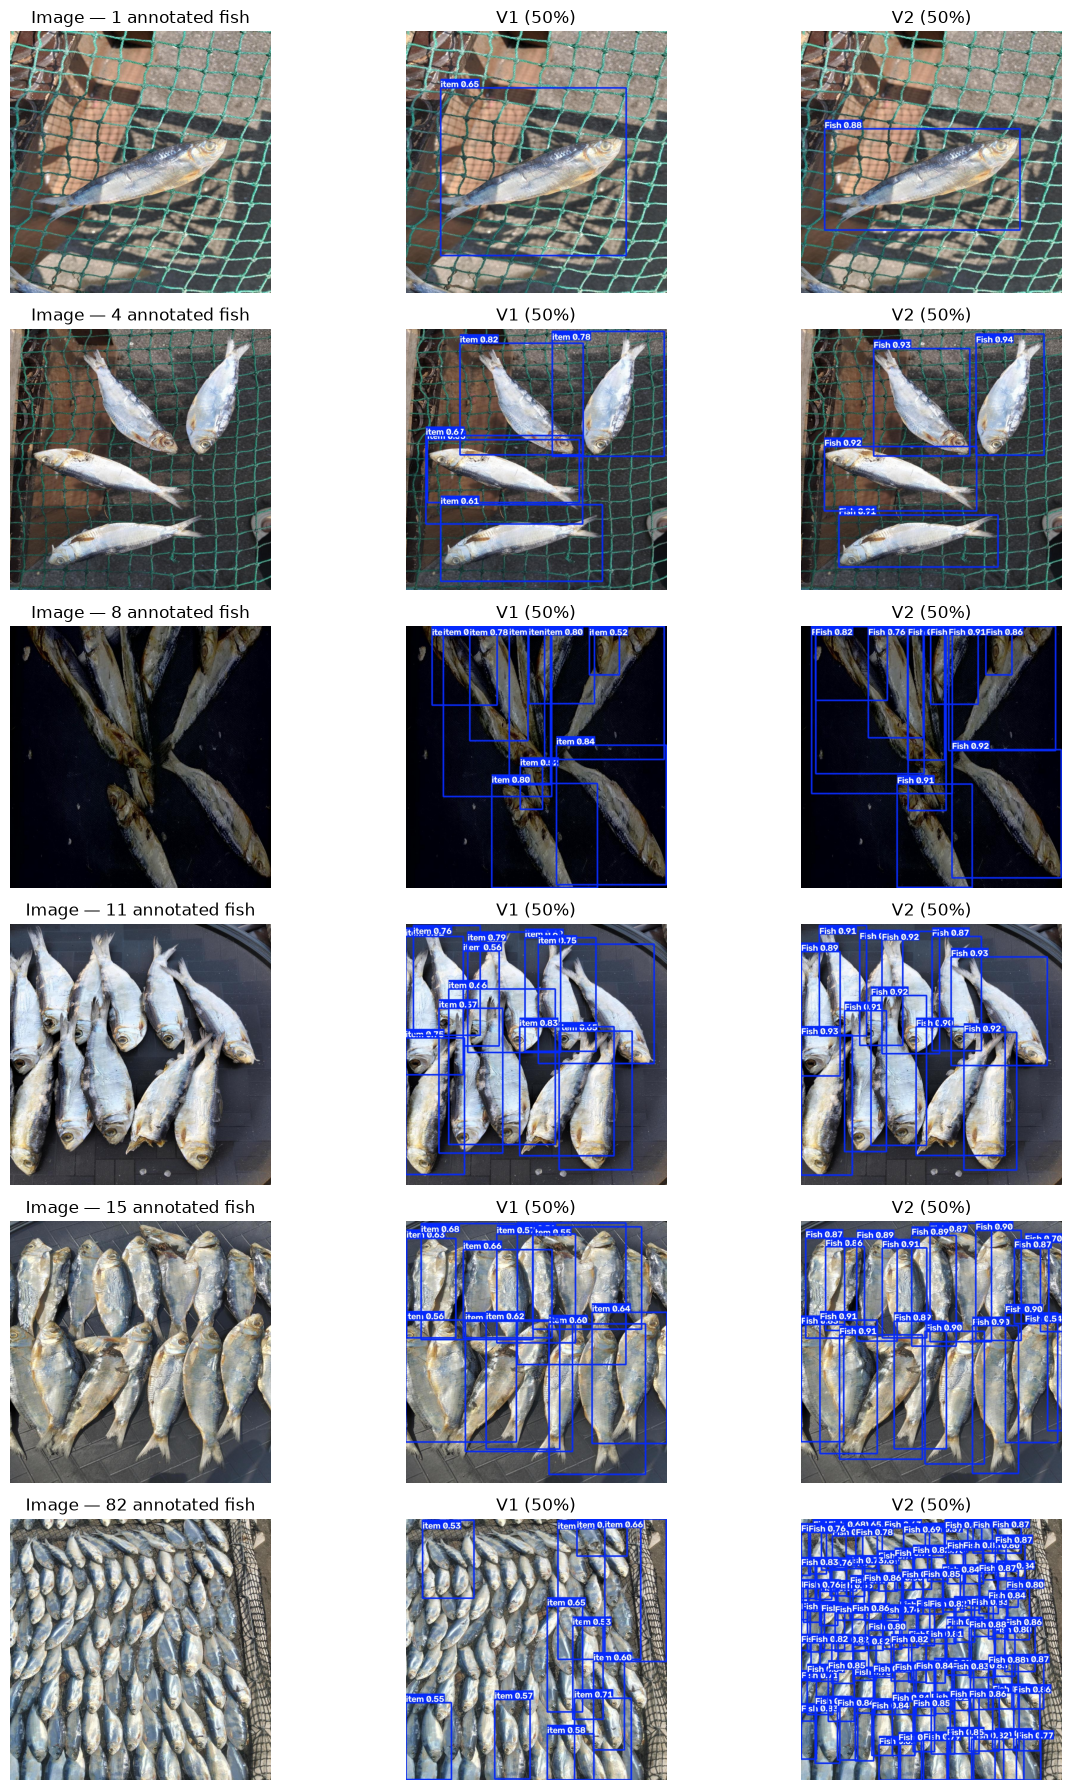


======== FINAL V1 VS V2 COMPARISON ========
       precision  recall   mAP50  mAP50_95  MAE_at_0.50  MAE_at_0.70  best_count_MAE  best_count_threshold  best_exact_count_accuracy
model                                                                                                                                
V1        0.5726  0.5434  0.5285    0.2611       4.5831       8.8169          4.0102                   0.4                     0.2034
V2        0.9462  0.9130  0.9725    0.8623       1.7763       1.5220          1.5220                   0.7                     0.4780

Best validation mAP50-95: V2
Best validation count MAE: V2

Reports and images saved in: C:\Users\User\Downloads\Tamban_Thesis_Main_Repository\Thesis\sardinella-lemuru-ml\notebooks\Tamban_Model1_Retrain\Model1_V1_vs_V2_Comparison

No training performed. Neither model was modified or replaced.
CAUTION: If V1 previously saw some of these validation images during training, this comparison is not fully independent.


In [6]:

# ============================================================
# TAMBAN MODEL 1: V1 vs V2 — COMPLETE COMPARISON
# ONE COPY-PASTE JUPYTER CELL
# NO EXTRACT, NO PREPROCESSING, NO RETRAINING
# ============================================================

from pathlib import Path
import gc
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import yaml
from ultralytics import YOLO

# ----------------------- PATHS -----------------------

BASE = Path(
    r"C:\Users\User\Downloads\Tamban_Thesis_Main_Repository"
    r"\Thesis\sardinella-lemuru-ml\notebooks"
)

# Automatically locate the current V1 checkpoint.
# If multiple copies exist, specify the exact active path.
V1_PATH = None

# Your ORIGINAL best model — NOT Stage 2
V2_PATH = (
    BASE / "Tamban_Model1_Retrain"
    / "model1_20261101T161439Z"
    / "runs"
    / "model1_yolo26s"
    / "weights"
    / "best.pt"
)

DATA_YAML = (
    BASE / "tamban_model1_1900_work"
    / "yolo_cleaned"
    / "data.yaml"
)

OUT = (
    BASE / "Tamban_Model1_Retrain"
    / "Model1_V1_vs_V2_Comparison"
)

IMG_SIZE = 768
MAX_DET = 132
NMS_IOU = 0.70

DEVICE = 0 if torch.cuda.is_available() else "cpu"

CONF_GRID = np.round(
    np.arange(0.05, 0.81, 0.05), 2
)

VISUAL_CONF = 0.50
VISUAL_COUNT = 6


# ----------------------- HELPERS -----------------------

def hash_file(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)

    return h.hexdigest()


def find_v1():
    if V1_PATH is not None:
        p = Path(V1_PATH)

        if not p.is_file():
            raise FileNotFoundError(
                f"V1_PATH missing: {p}"
            )

        return p

    matches = sorted(
        BASE.parent.parent.rglob(
            "model1_fish_parent_detector.pt"
        )
    )

    if len(matches) == 0:
        raise FileNotFoundError(
            "V1 not found. Set V1_PATH to the "
            "active model's full path."
        )

    if len(matches) > 1:
        print("Multiple V1 files found:")

        for p in matches:
            print(p)

        raise RuntimeError(
            "Specify V1_PATH to avoid comparing "
            "the wrong model."
        )

    return matches[0]


def load_validation_images():
    cfg = yaml.safe_load(
        DATA_YAML.read_text(encoding="utf-8")
    )

    names = cfg.get("names", {})

    if len(names) != 1 or int(cfg.get("nc", 1)) != 1:
        raise RuntimeError(
            f"Expected one Fish class, found {names}"
        )

    root = Path(
        str(cfg.get("path") or DATA_YAML.parent)
    )

    if not root.is_absolute():
        root = (
            DATA_YAML.parent / root
        ).resolve()

    images_dir = Path(str(cfg["val"]))

    if not images_dir.is_absolute():
        images_dir = root / images_dir

    labels_dir = root / "labels" / "val"

    if (
        not images_dir.is_dir()
        or not labels_dir.is_dir()
    ):
        raise FileNotFoundError(
            f"Check data.yaml path. Missing "
            f"{images_dir} or {labels_dir}"
        )

    entries = []

    for image in sorted(images_dir.iterdir()):

        if image.suffix.lower() not in {
            ".jpg", ".jpeg", ".png",
            ".bmp", ".webp"
        }:
            continue

        label = labels_dir / (
            image.stem + ".txt"
        )

        if not label.is_file():
            raise FileNotFoundError(
                f"Missing annotation: {label}"
            )

        lines = [
            x.split()
            for x in label.read_text(
                encoding="utf-8"
            ).splitlines()
            if x.strip()
        ]

        if any(
            len(x) != 5 or x[0] != "0"
            for x in lines
        ):
            raise ValueError(
                f"Bad YOLO annotation: {label}"
            )

        entries.append(
            (image, len(lines))
        )

    if not entries:
        raise RuntimeError(
            "No validation images found"
        )

    return entries


def clear_gpu():
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def count_stats(conf_arrays, gt, threshold):

    pred = np.array([
        int((c >= threshold).sum())
        for c in conf_arrays
    ])

    err = pred - gt

    return {
        "confidence": float(threshold),
        "MAE": float(np.abs(err).mean()),
        "RMSE": float(
            np.sqrt(
                np.mean(err.astype(float) ** 2)
            )
        ),
        "bias": float(err.mean()),
        "exact_accuracy": float(
            (pred == gt).mean()
        ),
        "within_one": float(
            (np.abs(err) <= 1).mean()
        )
    }


# ----------------------- COMPARE -----------------------

if not DATA_YAML.is_file():
    raise FileNotFoundError(
        f"Missing dataset YAML: {DATA_YAML}"
    )

if not V2_PATH.is_file():
    raise FileNotFoundError(
        f"Missing V2 checkpoint: {V2_PATH}"
    )

V1 = find_v1()

if hash_file(V1) == hash_file(V2_PATH):
    raise RuntimeError(
        "V1 and V2 files are identical. "
        "Verify V1_PATH."
    )

OUT.mkdir(
    parents=True,
    exist_ok=True
)

(OUT / "metrics").mkdir(
    exist_ok=True
)

entries = load_validation_images()

gt = np.array([
    n for _, n in entries
], dtype=int)

ordered = sorted(
    entries,
    key=lambda x: x[1]
)

samples = [
    ordered[i]
    for i in np.linspace(
        0,
        len(ordered) - 1,
        min(VISUAL_COUNT, len(ordered)),
        dtype=int
    )
]

print("=" * 60)
print("MODEL 1 V1 VS V2 COMPARISON")
print("=" * 60)

print("V1:", V1)
print("V2:", V2_PATH)

print(
    "Device:",
    torch.cuda.get_device_name(0)
    if DEVICE == 0 else "CPU"
)

print(
    "Same validation dataset:",
    len(entries),
    "images,",
    gt.sum(),
    "fish"
)

all_metrics = []
all_thresholds = []
metadata = {}

clear_gpu()

for name, checkpoint in [
    ("V1", V1),
    ("V2", V2_PATH)
]:

    print(f"\n========= {name} =========")

    model = YOLO(str(checkpoint))

    if (
        model.task != "detect"
        or len(model.names) != 1
    ):
        raise RuntimeError(
            f"{name} isn't a one-class "
            f"fish detector: {model.names}"
        )

    metadata[name] = {
        "checkpoint": str(checkpoint),
        "sha256": hash_file(checkpoint),
        "classes": model.names
    }

    # ---------------- DETECTION EVALUATION ----------------

    m = model.val(
        data=str(DATA_YAML),
        split="val",
        imgsz=IMG_SIZE,
        device=DEVICE,
        batch=1,
        workers=0,
        conf=0.001,
        iou=NMS_IOU,
        max_det=MAX_DET,
        plots=True,
        verbose=False,
        project=str(
            OUT / "validation_plots"
        ),
        name=name,
        exist_ok=True
    )

    detection = {
        "precision": float(m.box.mp),
        "recall": float(m.box.mr),
        "mAP50": float(m.box.map50),
        "mAP50_95": float(m.box.map)
    }

    print("Detection:", detection)

    del m
    clear_gpu()

    # ---------------- MEMORY-SAFE COUNTING ----------------

    arrays = []

    for i, (image, _) in enumerate(
        entries, 1
    ):

        confs = np.empty(
            0,
            dtype=np.float32
        )

        with torch.inference_mode():

            for res in model.predict(
                source=str(image),
                conf=0.01,
                imgsz=IMG_SIZE,
                iou=NMS_IOU,
                max_det=MAX_DET,
                device=DEVICE,
                batch=1,
                stream=True,
                save=False,
                verbose=False
            ):

                if (
                    res.boxes is not None
                    and len(res.boxes)
                ):
                    confs = (
                        res.boxes.conf
                        .detach()
                        .cpu()
                        .numpy()
                        .copy()
                    )

        arrays.append(confs)

        if (
            i % 50 == 0
            or i == len(entries)
        ):
            print(
                f"Counting {i}/{len(entries)} images"
            )

    # ---------------- COUNT THRESHOLD COMPARISON ----------------

    candidates = []

    for threshold in CONF_GRID:

        row = count_stats(
            arrays,
            gt,
            float(threshold)
        )

        all_thresholds.append({
            "model": name,
            **row
        })

        candidates.append(row)

    candidates.sort(
        key=lambda r: (
            r["MAE"],
            -r["exact_accuracy"],
            r["confidence"]
        )
    )

    best = candidates[0]

    fixed50 = count_stats(
        arrays, gt, 0.50
    )

    fixed70 = count_stats(
        arrays, gt, 0.70
    )

    print(
        "Best counting threshold:",
        best
    )

    all_metrics.append({
        "model": name,
        **detection,
        "MAE_at_0.50": fixed50["MAE"],
        "MAE_at_0.70": fixed70["MAE"],
        "best_count_MAE": best["MAE"],
        "best_count_threshold": best["confidence"],
        "best_exact_count_accuracy":
            best["exact_accuracy"]
    })

    del arrays
    clear_gpu()

    # ---------------- VISUAL EXAMPLES ----------------

    preview_dir = (
        OUT / "previews" / name
    )

    preview_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    for j, (image, _) in enumerate(samples):

        with torch.inference_mode():

            for res in model.predict(
                source=str(image),
                conf=VISUAL_CONF,
                imgsz=IMG_SIZE,
                iou=NMS_IOU,
                max_det=MAX_DET,
                device=DEVICE,
                batch=1,
                stream=True,
                save=False,
                verbose=False
            ):

                cv2.imwrite(
                    str(
                        preview_dir /
                        f"{j:02d}.jpg"
                    ),
                    res.plot()
                )

    del model
    clear_gpu()


# ----------------------- SAVE RESULTS -----------------------

summary = (
    pd.DataFrame(all_metrics)
    .set_index("model")
    .loc[["V1", "V2"]]
)

tuning = pd.DataFrame(
    all_thresholds
)

summary.to_csv(
    OUT / "metrics" /
    "comparison_summary.csv"
)

tuning.to_csv(
    OUT / "metrics" /
    "counting_thresholds.csv",
    index=False
)

(
    OUT / "metrics" /
    "checkpoint_metadata.json"
).write_text(
    json.dumps(
        metadata,
        indent=2,
        default=str
    ),
    encoding="utf-8"
)


# ----------------------- DETECTION GRAPH -----------------------

fig, ax = plt.subplots(
    figsize=(10, 5)
)

(
    summary[
        [
            "precision",
            "recall",
            "mAP50",
            "mAP50_95"
        ]
    ].T * 100
).plot.bar(ax=ax)

ax.set_ylim(0, 100)
ax.set_ylabel("Validation score (%)")
ax.set_title(
    "Model 1 V1 vs V2 — Detection Performance"
)

ax.tick_params(
    axis="x",
    rotation=0
)

ax.grid(
    axis="y",
    alpha=0.25
)

fig.tight_layout()

fig.savefig(
    OUT / "metrics" /
    "detection_comparison.png",
    dpi=180
)

plt.show()
plt.close(fig)


# ----------------------- COUNTING GRAPH -----------------------

fig, ax = plt.subplots(
    figsize=(8, 4)
)

for name in ("V1", "V2"):

    rows = tuning[
        tuning.model == name
    ].sort_values("confidence")

    ax.plot(
        rows.confidence,
        rows.MAE,
        marker="o",
        label=name
    )

ax.set_title(
    "Fish-count MAE on validation"
)

ax.set_xlabel(
    "Confidence threshold"
)

ax.set_ylabel(
    "Mean absolute error (fish/image)"
)

ax.grid(alpha=0.25)
ax.legend()

fig.tight_layout()

fig.savefig(
    OUT / "metrics" /
    "counting_comparison.png",
    dpi=180
)

plt.show()
plt.close(fig)


# ----------------------- SIDE-BY-SIDE IMAGES -----------------------

fig, axes = plt.subplots(
    len(samples),
    3,
    figsize=(13, 3 * len(samples)),
    squeeze=False
)

for i, (image, count) in enumerate(samples):

    files = [
        image,
        OUT / "previews" /
            "V1" / f"{i:02d}.jpg",
        OUT / "previews" /
            "V2" / f"{i:02d}.jpg"
    ]

    titles = [
        f"Image — {count} annotated fish",
        "V1 (50%)",
        "V2 (50%)"
    ]

    for j, file in enumerate(files):

        bgr = cv2.imread(
            str(file)
        )

        if bgr is None:
            raise RuntimeError(
                f"Cannot open preview: {file}"
            )

        axes[i, j].imshow(
            cv2.cvtColor(
                bgr,
                cv2.COLOR_BGR2RGB
            )
        )

        axes[i, j].set_title(
            titles[j]
        )

        axes[i, j].axis("off")

fig.tight_layout()

fig.savefig(
    OUT / "metrics" /
    "side_by_side.png",
    dpi=130
)

plt.show()
plt.close(fig)


# ----------------------- FINAL SUMMARY -----------------------

print(
    "\n======== FINAL V1 VS V2 COMPARISON ========"
)

print(
    summary.round(4).to_string()
)

print(
    "\nBest validation mAP50-95:",
    summary.mAP50_95.idxmax()
)

print(
    "Best validation count MAE:",
    summary.best_count_MAE.idxmin()
)

print(
    "\nReports and images saved in:",
    OUT
)

print(
    "\nNo training performed. "
    "Neither model was modified or replaced."
)

print(
    "CAUTION: If V1 previously saw some of these "
    "validation images during training, this "
    "comparison is not fully independent."
)
